# Практическая работа № 7. Случайный лес

**Цель:** сравнить дерево решений и случайный лес, оценить качество классификации и определить наиболее важные признаки.

Для классификации создаётся целевая переменная: высокий доход — доход не ниже 70-го процентиля. Столбец дохода не используется как входной признак, чтобы избежать утечки целевой информации.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

df = pd.read_csv("customers_dirty.csv")

print("Размер датасета:", df.shape)
display(df.head())
print("Столбцы:", df.columns.tolist())
print("Пропуски:")
display(df.isna().sum())

Размер датасета: (30, 6)


,customer_id,age,monthly_income,city,visits_per_month,satisfaction_score
0,1,19.0,18000.0,Бишкек,5,8.0
1,2,22.0,25000.0,Ош,8,9.0
2,3,25.0,32000.0,Бишкек,12,7.0
3,4,31.0,45000.0,Каракол,6,8.0
4,5,28.0,38000.0,Ош,10,9.0


Столбцы: ['customer_id', 'age', 'monthly_income', 'city', 'visits_per_month', 'satisfaction_score']
Пропуски:


customer_id           0
age                   1
monthly_income        1
city                  0
visits_per_month      0
satisfaction_score    1
dtype: int64

In [2]:
# Создаём целевую переменную на основе дохода
if "monthly_income" not in df.columns:
    raise ValueError("В датасете не найден столбец monthly_income. Проверь название столбца.")

df = df.dropna(subset=["monthly_income"]).copy()
threshold = df["monthly_income"].quantile(0.70)
df["high_income"] = (df["monthly_income"] >= threshold).astype(int)

# Доход исключаем из X, потому что он использован для создания целевой переменной
X = df.drop(columns=["monthly_income", "high_income"])
y = df["high_income"]

# Удаляем столбцы, в которых нет ни одного значения
X = X.dropna(axis=1, how="all")

# Определяем числовые и категориальные признаки
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []
if numeric_features:
    transformers.append(("num", numeric_pipeline, numeric_features))
if categorical_features:
    transformers.append(("cat", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Порог высокого дохода:", round(threshold, 2))
print("Размер train:", X_train.shape)
print("Размер test:", X_test.shape)
print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)

Порог высокого дохода: 45600.0
Размер train: (23, 5)
Размер test: (6, 5)
Числовые признаки: ['customer_id', 'age', 'visits_per_month', 'satisfaction_score']
Категориальные признаки: ['city']


In [3]:
# Обучаем дерево решений
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42, max_depth=5))
])

tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_test)

# Обучаем случайный лес на том же разбиении данных
forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        max_depth=10,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_test)

print("Дерево решений:")
print(classification_report(y_test, tree_predictions, zero_division=0))
print("Случайный лес:")
print(classification_report(y_test, forest_predictions, zero_division=0))

Дерево решений:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

Случайный лес:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



In [4]:
# Сравниваем модели по одинаковым метрикам
results = pd.DataFrame([
    {
        "Модель": "Decision Tree",
        "Accuracy": accuracy_score(y_test, tree_predictions),
        "F1": f1_score(y_test, tree_predictions, zero_division=0)
    },
    {
        "Модель": "Random Forest (100 деревьев)",
        "Accuracy": accuracy_score(y_test, forest_predictions),
        "F1": f1_score(y_test, forest_predictions, zero_division=0)
    }
])

display(results.round(3))

print("В случайном лесу 100 деревьев. Это распространённый базовый выбор, позволяющий объединить предсказания многих деревьев и получить более стабильный результат.")

,Модель,Accuracy,F1
0,Decision Tree,1.0,1.0
1,Random Forest (100 деревьев),1.0,1.0


В случайном лесу 100 деревьев. Это распространённый базовый выбор, позволяющий объединить предсказания многих деревьев и получить более стабильный результат.


,Признак,Важность
1,num__age,0.4736
2,num__visits_per_month,0.2611
0,num__customer_id,0.1292
3,num__satisfaction_score,0.0771
6,cat__city_Ош,0.0244
4,cat__city_Бишкек,0.0143
5,cat__city_Каракол,0.0111
7,cat__city_неизвестно,0.0091


Два наиболее важных признака:
- num__age: 0.4736
- num__visits_per_month: 0.2611


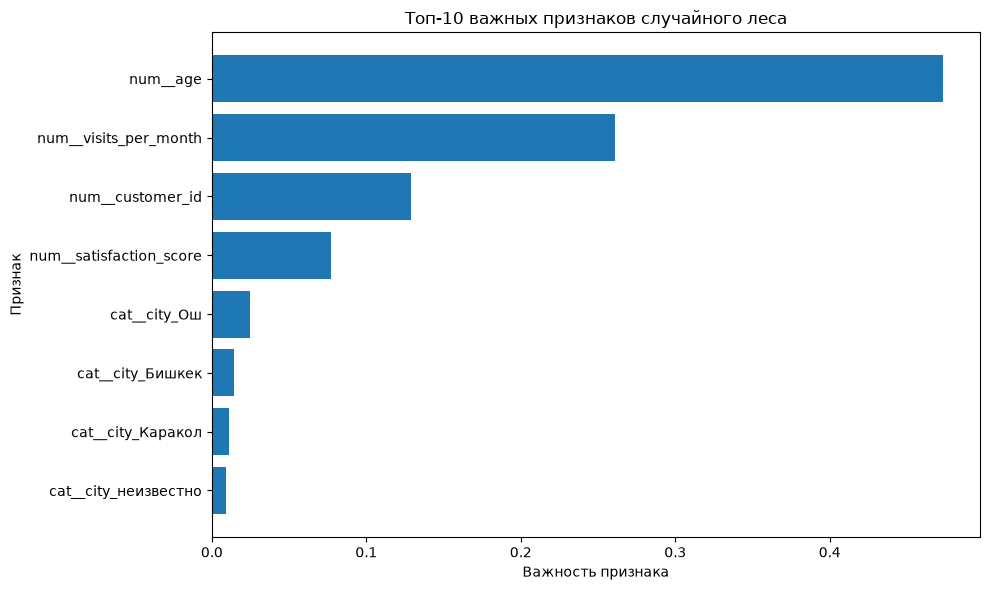

In [5]:
# Важность признаков случайного леса
trained_preprocessor = forest_model.named_steps["preprocessor"]
trained_forest = forest_model.named_steps["model"]

feature_names = trained_preprocessor.get_feature_names_out()
importances = trained_forest.feature_importances_

importance_df = pd.DataFrame({
    "Признак": feature_names,
    "Важность": importances
}).sort_values("Важность", ascending=False)

display(importance_df.head(10).round(4))

top_features = importance_df.head(2)
print("Два наиболее важных признака:")
for _, row in top_features.iterrows():
    print(f"- {row['Признак']}: {row['Важность']:.4f}")

plot_data = importance_df.head(10).sort_values("Важность")
plt.figure(figsize=(10, 6))
plt.barh(plot_data["Признак"], plot_data["Важность"])
plt.xlabel("Важность признака")
plt.ylabel("Признак")
plt.title("Топ-10 важных признаков случайного леса")
plt.tight_layout()
plt.show()

## Выводы

1. Дерево решений и случайный лес обучены на одном и том же train-наборе и оценены на одном test-наборе.
2. Accuracy и F1 позволяют сравнить качество моделей. Лучшую модель определяем по полученным значениям, а не заранее.
3. Случайный лес объединяет предсказания 100 деревьев и часто работает стабильнее одиночного дерева.
4. Два самых важных признака определяются по таблице и графику выше.
5. Важность показывает, насколько признак использовался моделью для предсказаний, но не доказывает причинно-следственную связь.